# EDA Lenta

In [ ]:
!pip install scikit-uplift

In [ ]:
from sklift.datasets import fetch_lenta
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

## Описание датасета


Датасет содержит данные о покупках продуктов клиентами «Ленты» и соответствующих маркетинговых кампаниях.

Описание фичей:
| Признак | Описание |
|---|---|
| `CardHolder` | ID клиента |
| `customer_age` | возраст клиента |
| `children` | количество детей |
| `cheque_count_[3,6,12]m_g*` | число чеков клиента за 3, 6 и 12 месяцев до кампании; `g*` означает товарную группу |
| `crazy_purchases_cheque_count_[1,3,6,12]m` | число чеков с товарами, купленными в рамках маркетинговой акции «crazy», за 1, 3, 6 и 12 месяцев до кампании |
| `crazy_purchases_goods_count_[6,12]m` | количество товаров, купленных в рамках акции «crazy», за 6 и 12 месяцев до кампании |
| `disc_sum_6m_g34` | сумма скидок за последние 6 месяцев по товарной группе 34 |
| `food_share_[15d,1m]` | доля продуктов питания в покупках клиента за 15 дней и 1 месяц |
| `gender` | пол клиента |
| `group` | флаг группы: treatment (воздействие) или control (контроль) |
| `k_var_cheque_[15d,3m]` | коэффициент вариации среднего чека за 15 дней и 3 месяца |
| `k_var_cheque_category_width_15d` | коэффициент вариации среднего числа категорий (2-й уровень иерархии) в одном чеке за 15 дней |
| `k_var_cheque_group_width_15d` | коэффициент вариации среднего числа групп (1-й уровень иерархии) в одном чеке за 15 дней |
| `k_var_count_per_cheque_[15d,1m,3m,6m]_g*` | коэффициент вариации числа уникальных товаров (SKU) за 15 дней, 1, 3 и 6 месяцев по группе `g*` |
| `k_var_days_between_visits_[15d,1m,3m]` | коэффициент вариации среднего интервала между визитами за 15 дней, 1 и 3 месяца |
| `k_var_disc_per_cheque_15d` | коэффициент вариации суммы скидки за 15 дней |
| `k_var_disc_share_[15d,1m,3m,6m,12m]_g*` | коэффициент вариации размера скидки за 15 дней, 1, 3, 6 и 12 месяцев по группе `g*` |
| `k_var_discount_depth_[15d,1m]` | коэффициент вариации размера скидки за 15 дней и 1 месяц |
| `k_var_sku_per_cheque_15d` | коэффициент вариации числа уникальных товаров (SKU) в чеке за 15 дней |
| `k_var_sku_price_[15d,1m,3m,6m,12m]_g*` | коэффициент вариации цены за 15 дней, 1, 3, 6 и 12 месяцев по группе `g*` (в исходной документации ошибочно указан только 12m) |
| `main_format` | тип магазина (1 = магазин у дома, 0 = супермаркет) |
| `mean_discount_depth_15d` | средняя глубина скидки за 15 дней |
| `months_from_register` | число месяцев с момента регистрации |
| `perdelta_days_between_visits_15_30d` | разница в процентах между интервалами визитов в первой и во второй половине месяца |
| `promo_share_15d` | доля промотоваров в корзине клиента |
| `response_att` | бинарный таргет: визит в магазин |
| `response_sms` | доля откликов на прошлые SMS (отклик означает визит в магазин) |
| `response_viber` | доля откликов на прошлые сообщения в Viber (отклик означает визит в магазин) |
| `sale_count_[3,6,12]m_g*` | количество купленных товаров из группы `g*` за 3, 6 и 12 месяцев |
| `sale_sum_[3,6,12]m_g*` | сумма продаж по группе `g*` за 3, 6 и 12 месяцев |
| `stdev_days_between_visits_15d` | стнд. отклонение числа дней между визитами за 15 дней |
| `stdev_discount_depth_[15d,1m]` | стнд. отклонение суммы скидки за 15 дней и 1 месяц |

## 1. Общая информация

In [ ]:
dataset = fetch_lenta()
data, target, treatment = dataset.data, dataset.target, dataset.treatment

In [ ]:
print('Размеры data:', data.shape)
print('Размеры target:', target.shape)
print('Размеры treatment:', treatment.shape)

Размеры data: (687029, 193)
Размеры target: (687029,)
Размеры treatment: (687029,)


In [ ]:
data.head()

,age,cheque_count_12m_g20,cheque_count_12m_g21,cheque_count_12m_g25,cheque_count_12m_g32,cheque_count_12m_g33,cheque_count_12m_g38,cheque_count_12m_g39,cheque_count_12m_g41,cheque_count_12m_g42,cheque_count_12m_g45,cheque_count_12m_g46,cheque_count_12m_g48,cheque_count_12m_g52,cheque_count_12m_g56,cheque_count_12m_g57,cheque_count_12m_g58,cheque_count_12m_g79,cheque_count_3m_g20,cheque_count_3m_g21,cheque_count_3m_g25,cheque_count_3m_g42,cheque_count_3m_g45,cheque_count_3m_g52,cheque_count_3m_g56,cheque_count_3m_g57,cheque_count_3m_g79,cheque_count_6m_g20,cheque_count_6m_g21,cheque_count_6m_g25,cheque_count_6m_g32,cheque_count_6m_g33,cheque_count_6m_g38,cheque_count_6m_g39,cheque_count_6m_g40,cheque_count_6m_g41,cheque_count_6m_g42,cheque_count_6m_g45,cheque_count_6m_g46,cheque_count_6m_g48,cheque_count_6m_g52,cheque_count_6m_g56,cheque_count_6m_g57,cheque_count_6m_g58,cheque_count_6m_g79,children,crazy_purchases_cheque_count_12m,crazy_purchases_cheque_count_1m,crazy_purchases_cheque_count_3m,crazy_purchases_cheque_count_6m,crazy_purchases_goods_count_12m,crazy_purchases_goods_count_6m,disc_sum_6m_g34,food_share_15d,food_share_1m,gender,k_var_cheque_15d,k_var_cheque_3m,k_var_cheque_category_width_15d,k_var_cheque_group_width_15d,k_var_count_per_cheque_15d_g24,k_var_count_per_cheque_15d_g34,k_var_count_per_cheque_1m_g24,k_var_count_per_cheque_1m_g27,k_var_count_per_cheque_1m_g34,k_var_count_per_cheque_1m_g44,k_var_count_per_cheque_1m_g49,k_var_count_per_cheque_3m_g24,k_var_count_per_cheque_3m_g27,k_var_count_per_cheque_3m_g32,k_var_count_per_cheque_3m_g34,k_var_count_per_cheque_3m_g41,k_var_count_per_cheque_3m_g44,k_var_count_per_cheque_6m_g24,k_var_count_per_cheque_6m_g27,k_var_count_per_cheque_6m_g32,k_var_count_per_cheque_6m_g44,k_var_days_between_visits_15d,k_var_days_between_visits_1m,k_var_days_between_visits_3m,k_var_disc_per_cheque_15d,k_var_disc_share_12m_g32,k_var_disc_share_15d_g24,k_var_disc_share_15d_g34,k_var_disc_share_15d_g49,k_var_disc_share_1m_g24,k_var_disc_share_1m_g27,k_var_disc_share_1m_g34,k_var_disc_share_1m_g40,k_var_disc_share_1m_g44,k_var_disc_share_1m_g49,k_var_disc_share_1m_g54,k_var_disc_share_3m_g24,k_var_disc_share_3m_g26,k_var_disc_share_3m_g27,k_var_disc_share_3m_g32,k_var_disc_share_3m_g33,k_var_disc_share_3m_g34,k_var_disc_share_3m_g38,k_var_disc_share_3m_g40,k_var_disc_share_3m_g41,k_var_disc_share_3m_g44,k_var_disc_share_3m_g46,k_var_disc_share_3m_g48,k_var_disc_share_3m_g49,k_var_disc_share_3m_g54,k_var_disc_share_6m_g24,k_var_disc_share_6m_g27,k_var_disc_share_6m_g32,k_var_disc_share_6m_g34,k_var_disc_share_6m_g44,k_var_disc_share_6m_g46,k_var_disc_share_6m_g49,k_var_disc_share_6m_g54,k_var_discount_depth_15d,k_var_discount_depth_1m,k_var_sku_per_cheque_15d,k_var_sku_price_12m_g32,k_var_sku_price_15d_g34,k_var_sku_price_15d_g49,k_var_sku_price_1m_g24,k_var_sku_price_1m_g26,k_var_sku_price_1m_g27,k_var_sku_price_1m_g34,k_var_sku_price_1m_g40,k_var_sku_price_1m_g44,k_var_sku_price_1m_g49,k_var_sku_price_1m_g54,k_var_sku_price_3m_g24,k_var_sku_price_3m_g26,k_var_sku_price_3m_g27,k_var_sku_price_3m_g32,k_var_sku_price_3m_g33,k_var_sku_price_3m_g34,k_var_sku_price_3m_g40,k_var_sku_price_3m_g41,k_var_sku_price_3m_g44,k_var_sku_price_3m_g46,k_var_sku_price_3m_g48,k_var_sku_price_3m_g49,k_var_sku_price_3m_g54,k_var_sku_price_6m_g24,k_var_sku_price_6m_g26,k_var_sku_price_6m_g27,k_var_sku_price_6m_g32,k_var_sku_price_6m_g41,k_var_sku_price_6m_g42,k_var_sku_price_6m_g44,k_var_sku_price_6m_g48,k_var_sku_price_6m_g49,main_format,mean_discount_depth_15d,months_from_register,perdelta_days_between_visits_15_30d,promo_share_15d,response_sms,response_viber,sale_count_12m_g32,sale_count_12m_g33,sale_count_12m_g49,sale_count_12m_g54,sale_count_12m_g57,sale_count_3m_g24,sale_count_3m_g33,sale_count_3m_g57,sale_count_6m_g24,sale_count_6m_g25,sale_count_6m_g32,sale_count_6m_g33,sale_count_6m_g44,sale_count_6m_g54,sale_count_6m_g57,sale_sum_12m_g24,sale_sum_12m_g25,sale_sum_12m_g26,sale_sum_12m_g27,sale_sum_12m_

In [ ]:
data.describe()

,age,cheque_count_12m_g20,cheque_count_12m_g21,cheque_count_12m_g25,cheque_count_12m_g32,cheque_count_12m_g33,cheque_count_12m_g38,cheque_count_12m_g39,cheque_count_12m_g41,cheque_count_12m_g42,cheque_count_12m_g45,cheque_count_12m_g46,cheque_count_12m_g48,cheque_count_12m_g52,cheque_count_12m_g56,cheque_count_12m_g57,cheque_count_12m_g58,cheque_count_12m_g79,cheque_count_3m_g20,cheque_count_3m_g21,cheque_count_3m_g25,cheque_count_3m_g42,cheque_count_3m_g45,cheque_count_3m_g52,cheque_count_3m_g56,cheque_count_3m_g57,cheque_count_3m_g79,cheque_count_6m_g20,cheque_count_6m_g21,cheque_count_6m_g25,cheque_count_6m_g32,cheque_count_6m_g33,cheque_count_6m_g38,cheque_count_6m_g39,cheque_count_6m_g40,cheque_count_6m_g41,cheque_count_6m_g42,cheque_count_6m_g45,cheque_count_6m_g46,cheque_count_6m_g48,cheque_count_6m_g52,cheque_count_6m_g56,cheque_count_6m_g57,cheque_count_6m_g58,cheque_count_6m_g79,children,crazy_purchases_cheque_count_12m,crazy_purchases_cheque_count_1m,crazy_purchases_cheque_count_3m,crazy_purchases_cheque_count_6m,crazy_purchases_goods_count_12m,crazy_purchases_goods_count_6m,disc_sum_6m_g34,food_share_15d,food_share_1m,k_var_cheque_15d,k_var_cheque_3m,k_var_cheque_category_width_15d,k_var_cheque_group_width_15d,k_var_count_per_cheque_15d_g24,k_var_count_per_cheque_15d_g34,k_var_count_per_cheque_1m_g24,k_var_count_per_cheque_1m_g27,k_var_count_per_cheque_1m_g34,k_var_count_per_cheque_1m_g44,k_var_count_per_cheque_1m_g49,k_var_count_per_cheque_3m_g24,k_var_count_per_cheque_3m_g27,k_var_count_per_cheque_3m_g32,k_var_count_per_cheque_3m_g34,k_var_count_per_cheque_3m_g41,k_var_count_per_cheque_3m_g44,k_var_count_per_cheque_6m_g24,k_var_count_per_cheque_6m_g27,k_var_count_per_cheque_6m_g32,k_var_count_per_cheque_6m_g44,k_var_days_between_visits_15d,k_var_days_between_visits_1m,k_var_days_between_visits_3m,k_var_disc_per_cheque_15d,k_var_disc_share_12m_g32,k_var_disc_share_15d_g24,k_var_disc_share_15d_g34,k_var_disc_share_15d_g49,k_var_disc_share_1m_g24,k_var_disc_share_1m_g27,k_var_disc_share_1m_g34,k_var_disc_share_1m_g40,k_var_disc_share_1m_g44,k_var_disc_share_1m_g49,k_var_disc_share_1m_g54,k_var_disc_share_3m_g24,k_var_disc_share_3m_g26,k_var_disc_share_3m_g27,k_var_disc_share_3m_g32,k_var_disc_share_3m_g33,k_var_disc_share_3m_g34,k_var_disc_share_3m_g38,k_var_disc_share_3m_g40,k_var_disc_share_3m_g41,k_var_disc_share_3m_g44,k_var_disc_share_3m_g46,k_var_disc_share_3m_g48,k_var_disc_share_3m_g49,k_var_disc_share_3m_g54,k_var_disc_share_6m_g24,k_var_disc_share_6m_g27,k_var_disc_share_6m_g32,k_var_disc_share_6m_g34,k_var_disc_share_6m_g44,k_var_disc_share_6m_g46,k_var_disc_share_6m_g49,k_var_disc_share_6m_g54,k_var_discount_depth_15d,k_var_discount_depth_1m,k_var_sku_per_cheque_15d,k_var_sku_price_12m_g32,k_var_sku_price_15d_g34,k_var_sku_price_15d_g49,k_var_sku_price_1m_g24,k_var_sku_price_1m_g26,k_var_sku_price_1m_g27,k_var_sku_price_1m_g34,k_var_sku_price_1m_g40,k_var_sku_price_1m_g44,k_var_sku_price_1m_g49,k_var_sku_price_1m_g54,k_var_sku_price_3m_g24,k_var_sku_price_3m_g26,k_var_sku_price_3m_g27,k_var_sku_price_3m_g32,k_var_sku_price_3m_g33,k_var_sku_price_3m_g34,k_var_sku_price_3m_g40,k_var_sku_price_3m_g41,k_var_sku_price_3m_g44,k_var_sku_price_3m_g46,k_var_sku_price_3m_g48,k_var_sku_price_3m_g49,k_var_sku_price_3m_g54,k_var_sku_price_6m_g24,k_var_sku_price_6m_g26,k_var_sku_price_6m_g27,k_var_sku_price_6m_g32,k_var_sku_price_6m_g41,k_var_sku_price_6m_g42,k_var_sku_price_6m_g44,k_var_sku_price_6m_g48,k_var_sku_price_6m_g49,main_format,mean_discount_depth_15d,months_from_register,perdelta_days_between_visits_15_30d,promo_share_15d,response_sms,response_viber,sale_count_12m_g32,sale_count_12m_g33,sale_count_12m_g49,sale_count_12m_g54,sale_count_12m_g57,sale_count_3m_g24,sale_count_3m_g33,sale_count_3m_g57,sale_count_6m_g24,sale_count_6m_g25,sale_count_6m_g32,sale_count_6m_g33,sale_count_6m_g44,sale_count_6m_g54,sale_count_6m_g57,sale_sum_12m_g24,sale_sum_12m_g25,sale_sum_12m_g26,sale_sum_12m_g27,sale_sum_12m_g32,sal

In [ ]:
target.describe()

,response_att
count,687029.000000
mean,0.108246
std,0.310691
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


In [ ]:
treatment.describe()

,group
count,687029
unique,2
top,test
freq,515892


## 2. Пропуски

In [ ]:
na = pd.DataFrame({
    'na_share': data.isna().mean(),
    'na_test': data[treatment == 'test'].isna().mean(),
    'na_control': data[treatment == 'control'].isna().mean(),
})
na['diff_test_control'] = na['na_test'] - na['na_control']
na = na[na['na_share'] > 0].sort_values('na_share', ascending=False)

print(f'Признаков с пропусками: {len(na)} из {data.shape[1]}')
print(f'Максимальная разница доли NaN между test и control: {na["diff_test_control"].abs().max():.4f}')
na.head(15).round(4)

Признаков с пропусками: 153 из 193
Максимальная разница доли NaN между test и control: 0.0073


,na_share,na_test,na_control,diff_test_control
k_var_sku_price_15d_g49,0.7223,0.7209,0.7265,-0.0056
k_var_disc_share_15d_g49,0.7222,0.7208,0.7263,-0.0055
k_var_sku_price_15d_g34,0.6820,0.6811,0.6846,-0.0034
k_var_count_per_cheque_15d_g34,0.6820,0.6811,0.6846,-0.0034
k_var_disc_share_15d_g34,0.6819,0.6810,0.6844,-0.0034
k_var_count_per_cheque_15d_g24,0.6435,0.6422,0.6475,-0.0053
k_var_disc_share_15d_g24,0.6434,0.6421,0.6474,-0.0053
k_var_count_per_cheque_1m_g49,0.6033,0.6017,0.6082,-0.0065
k_var_sku_price_1m_g49,0.6033,0.6017,0.6082,-0.0065
k_var_disc_share_1m_g49,0.6031,0.6015,0.6080,-0.0065


**Вывод:**
- Пропуски есть у 153 из 193 признаков, у некоторых пропущено до 72% значений.
- Пропуски сбалансированы между группами: максимальная разница доли NaN между test и control 0.7 п.п. А также в основном информативны и обозначают отсутствие покупок по той или иной товарной группе за определенный период.

## 3. Аномалии в данных

### Возраст

In [ ]:
print(data['age'].describe(percentiles=[0.001, 0.01, 0.99, 0.999]).round(1))
print(f'\nВозраст < 14: {(data["age"] < 14).sum()}')
print(f'Возраст = 0:  {(data["age"] == 0).sum()}')
print(f'Возраст > 90: {(data["age"] > 90).sum()}')

count    675264.0
mean         43.7
std          14.8
min           0.0
0.1%         14.0
1%           18.0
50%          42.0
99%          78.0
99.9%        85.0
max         100.0
Name: age, dtype: float64

Возраст < 14: 330
Возраст = 0:  1
Возраст > 90: 129


### Отрицательные значения и диапазоны

- У числовых признаков отрицательных значений быть не должно.
- Доли (`food_share`, `promo_share`, `response_*`, `mean_discount_depth`) должны лежать в [0; 1].

In [ ]:
num_cols = data.select_dtypes('number').columns
print('Признаков с отрицательными значениями:', (data[num_cols] < 0).any().sum())

share_cols = ['food_share_15d', 'food_share_1m', 'promo_share_15d', 'response_sms', 'response_viber', 'mean_discount_depth_15d']
print('\nДиапазоны долей:')
print(data[share_cols].agg(['min', 'max']).T)

Признаков с отрицательными значениями: 0

Диапазоны долей:
                         min  max
food_share_15d           0.0  1.0
food_share_1m            0.0  1.0
promo_share_15d          0.0  1.0
response_sms             0.0  1.0
response_viber           0.0  1.0
mean_discount_depth_15d  0.0  1.0


**Вывод:**
- 330 клиентов младше 14 лет (один с возрастом 0) и 129 старше 90. Это 0.07% выборки, скорее всего ошибки ввода. Возраст < 14 можно заменить на NaN.
- Отрицательных значений нет, все доли в диапазоне [0; 1].

## 4. Дизайн эксперимента

### Распределение treatment и target групп

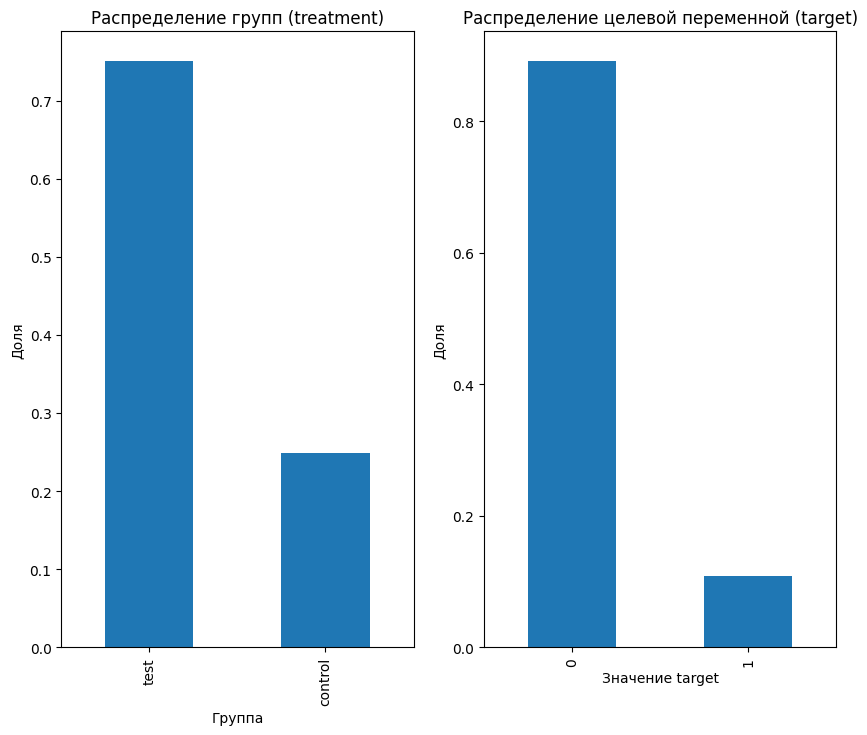

In [ ]:
# Распределение treatment и target
fig, ax = plt.subplots(1, 2, figsize = (10, 8))

trt = treatment.value_counts(normalize=True)
trg = target.value_counts(normalize=True)

trt.plot(kind = 'bar', ax = ax[0])
ax[0].set_xlabel('Группа')
ax[0].set_ylabel('Доля')
ax[0].set_title('Распределение групп (treatment)')

trg.plot(kind = 'bar', ax = ax[1])
ax[1].set_xlabel('Значение target')
ax[1].set_ylabel('Доля')
ax[1].set_title('Распределение целевой переменной (target)')

plt.show()

### Статистическая значимость

Так как мы сравниваем доли конверсии (бинарный признак) в двух независимых группах, используем Z-тест для пропорций.

**Гипотезы:**
* H0: Конверсии в контрольной и тестовой группах равны.
* H1: Конверсии различаются.

In [ ]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

treatment_target = pd.concat([treatment, target], axis = 1)
control_group = treatment_target[treatment_target['group'] == 'control']['response_att']
test_group = treatment_target[treatment_target['group'] == 'test']['response_att']

n_control = len(control_group)
n_test = len(test_group)
conv_control = control_group.sum()
conv_test = test_group.sum()

cr_control = conv_control / n_control
cr_test = conv_test / n_test

print(f'Конверсия Control: {cr_control:.4f}')
print(f'Конверсия Test: {cr_test:.4f}')

# Z-тест
stat, p_value = proportions_ztest([conv_test, conv_control], [n_test, n_control])

# ATE
ate = cr_test - cr_control

print(f"\nATE: {ate*100:.2f} п.п.")
print(f"Относительный uplift: {ate / cr_control:.1%}")
print(f"Z-statistic: {stat:.2f}")
print(f"P-value: {p_value:.2e}")

if p_value < 0.05:
    print("Вывод: Различия статистически ЗНАЧИМЫ (отвергаем H0)")
else:
    print("Вывод: Различия НЕ значимы (не отвергаем H0)")

Конверсия Control: 0.1026
Конверсия Test: 0.1101

ATE: 0.75 п.п.
Относительный uplift: 7.4%
Z-statistic: 8.71
P-value: 3.09e-18
Вывод: Различия статистически ЗНАЧИМЫ (отвергаем H0)


**ATE** (Average Treatment Effect) – средний эффект воздействия на всю выборку: насколько в среднем изменилась бы конверсия, если отправить рассылку всем, по сравнению с тем, если не отправлять никому.

ATE = конверсия_test − конверсия_control

**Вывод:**
- Сплит групп примерно 75/25 (test/control).
- Конверсия в test 11.01%, в control 10.26%. ATE = **+0.75 п.п.**, относительный uplift около **7.4%**.
- Эффект статистически значим (p < 0.05).

### Сбалансированность признаков

**SMD** (standardized mean difference, стандартизированная разница средних) показывает, насколько различаются средние признака в test и control, в единицах стандартного отклонения:

SMD = (среднее_test − среднее_control) / √((s²test + s²control) / 2)

In [ ]:
data['gender'].unique()

array(['Ж', 'М', nan, 'Не определен'], dtype=object)

In [ ]:
# Категориальный gender преобразуем в бинарные столбцы.
data_smd = data.copy()
data_smd['gender_f'] = (data_smd['gender'] == 'Ж').astype(int)
data_smd['gender_m'] = (data_smd['gender'] == 'М').astype(int)
data_smd['gender_undefined'] = ((data_smd['gender'] == 'Не определен') | (data_smd['gender'].isna())).astype(int)
data_smd = data_smd.drop(columns = ['gender'])

# По всем признакам считаем SMD
means = data_smd.groupby(treatment).mean()
vars_ = data_smd.groupby(treatment).var()
smd = (means.loc['test'] - means.loc['control']) / np.sqrt((vars_.loc['test'] + vars_.loc['control'])/2)

smd_table = pd.DataFrame({
    'mean_test': means.loc['test'],
    'mean_control': means.loc['control'],
    'smd': smd,
}).sort_values('smd', key=abs, ascending=False)

print('Признаков с |SMD| > 0.1:', (smd_table['smd'].abs() > 0.1).sum())
smd_table.head(20)

Признаков с |SMD| > 0.1: 1


,mean_test,mean_control,smd
response_sms,0.800636,0.726143,0.197907
response_viber,0.276202,0.250909,0.068491
gender_m,0.351878,0.364497,-0.026322
gender_f,0.633978,0.621631,0.025545
k_var_count_per_cheque_1m_g34,0.218477,0.210156,0.025344
crazy_purchases_cheque_count_12m,2.520365,2.406271,0.024931
crazy_purchases_goods_count_12m,4.243799,4.037707,0.024411
crazy_purchases_cheque_count_6m,1.078809,1.029339,0.023166
k_var_disc_share_1m_g34,0.262471,0.253222,0.022373
crazy_purchases_cheque_count_3m,0.585142,0.556928,0.021555


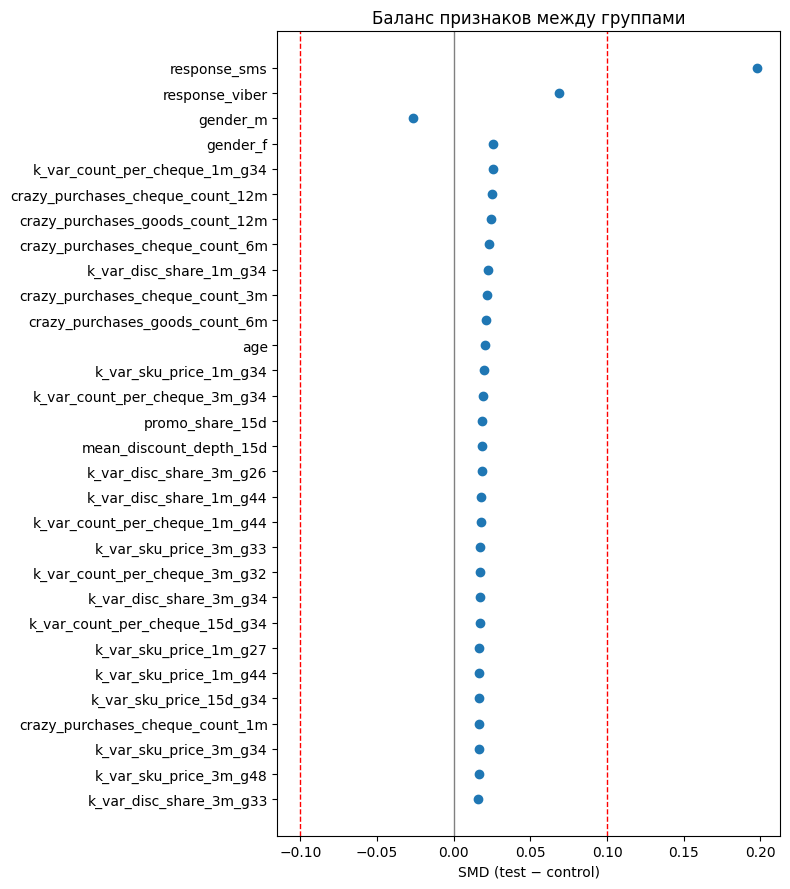

In [ ]:
top = smd_table.head(30).iloc[::-1]   # топ-30 по SMD

fig, ax = plt.subplots(figsize=(8, max(4, len(top) * 0.3)))
ax.scatter(top['smd'], top.index)
for x in (-0.1, 0.1):
    ax.axvline(x, color='red', linestyle='--', linewidth=1)   # пороги для сравнения
ax.axvline(0, color='grey', linewidth=1)
ax.set_xlabel('SMD (test − control)')
ax.set_title('Баланс признаков между группами')
plt.tight_layout()
plt.show()

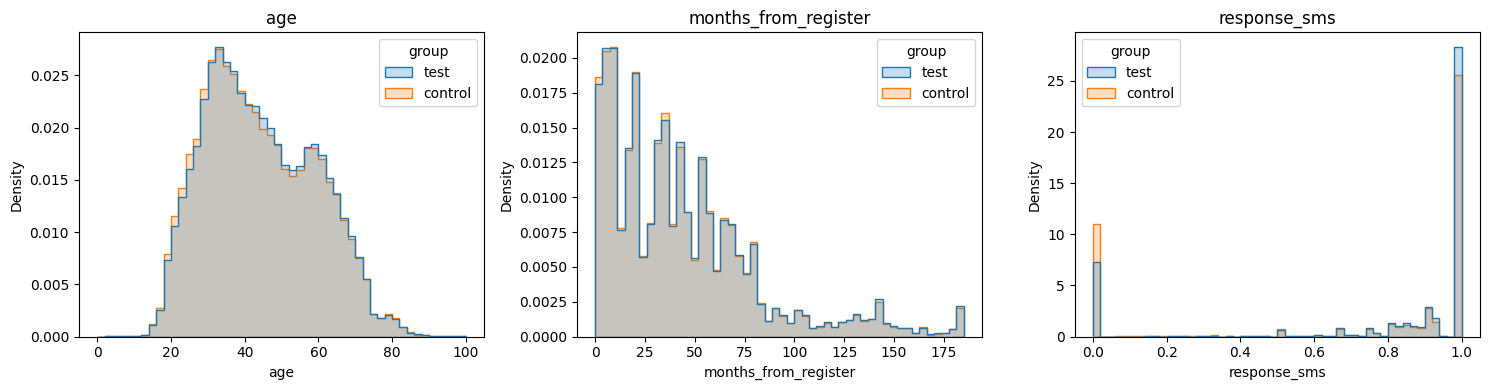

In [ ]:
cols = ['age', 'months_from_register', 'response_sms']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols):
    sns.histplot(x=data_smd[col], hue=treatment, stat='density',
                 common_norm=False, element='step', bins=50, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

**Вывод:**
- У 194 из 195 признаков |SMD| < 0.1, группы сбалансированы.
- Исключение: **`response_sms`, SMD ≈ 0.20** (0.80 в test против 0.73 в control).

## 5. Корреляционный анализ

Считаем на сэмпле 100 тыс. строк.

In [ ]:
corr_sample = data.drop(columns='gender').sample(100_000, random_state=42)
corr = corr_sample.corr(method='spearman')

# Пары признаков (каждая один раз, без диагонали)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
print(f'Всего пар: {len(upper)}')
print(f'Пар с коэфф. корреляции > 0.8: {(upper.abs() > 0.8).sum()}')
print(f'Пар с коэфф. корреляции > 0.9: {(upper.abs() > 0.9).sum()}')

Всего пар: 18336
Пар с коэфф. корреляции > 0.8: 326
Пар с коэфф. корреляции > 0.9: 105


### Корреляция внутри и между семействами признаков

Пример: число чеков `cheque_count` по одной товарной группе за разные периоды и по разным группам за один период.

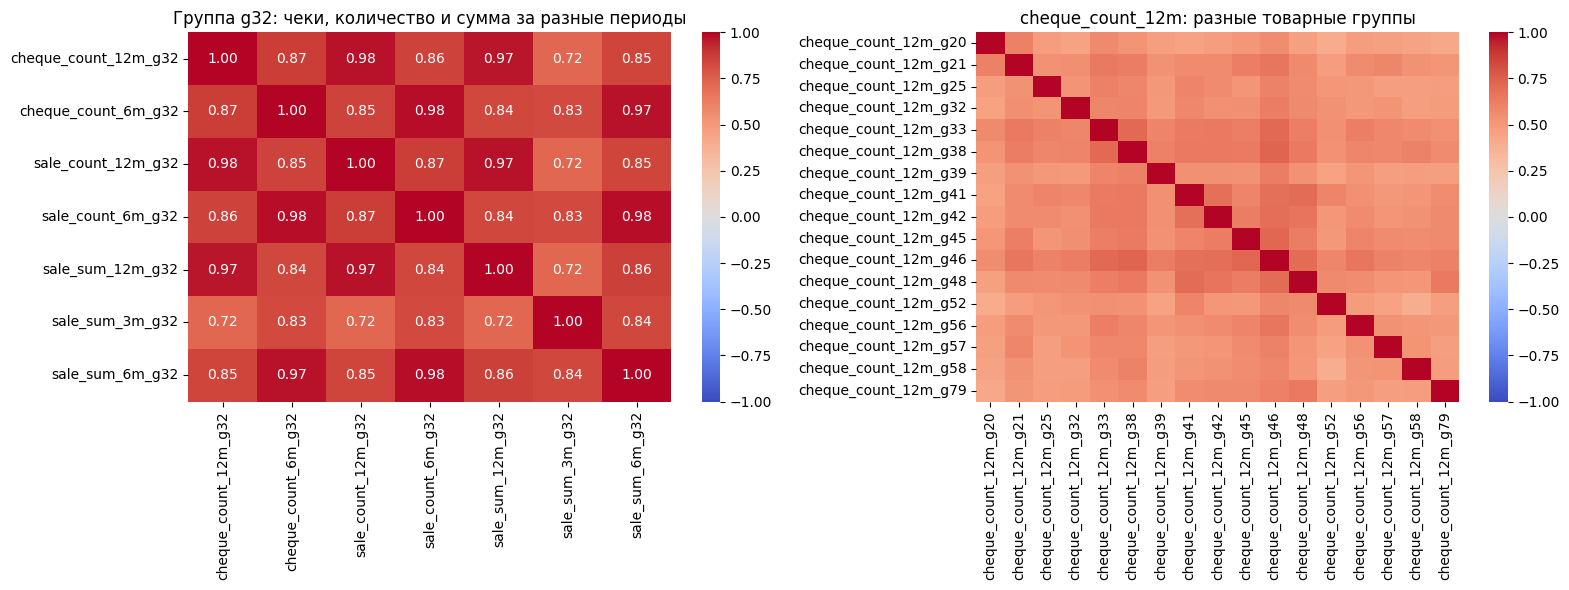

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cols_periods = [c for c in data.columns if c.startswith('cheque_count') and c.endswith('_g32')] + \
               [c for c in data.columns if c.startswith(('sale_count', 'sale_sum')) and c.endswith('_g32')]
sns.heatmap(corr.loc[cols_periods, cols_periods], annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Группа g32: чеки, количество и сумма за разные периоды')

cols_groups = [c for c in data.columns if c.startswith('cheque_count_12m')]
sns.heatmap(corr.loc[cols_groups, cols_groups], cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('cheque_count_12m: разные товарные группы')

plt.tight_layout()
plt.show()

In [ ]:
# Топ-20 пар по коэфф. коррелиции
top_pairs = upper.abs().sort_values(ascending=False).head(20)
top_pairs.to_frame('|rho|').round(3)

,,|rho|
k_var_days_between_visits_15d,stdev_days_between_visits_15d,0.998
cheque_count_3m_g57,sale_count_3m_g57,0.998
k_var_discount_depth_15d,stdev_discount_depth_15d,0.994
cheque_count_6m_g57,sale_count_6m_g57,0.993
cheque_count_12m_g57,sale_count_12m_g57,0.992
mean_discount_depth_15d,promo_share_15d,0.990
sale_count_3m_g33,sale_sum_3m_g33,0.986
sale_count_6m_g33,sale_sum_6m_g33,0.985
crazy_purchases_cheque_count_6m,crazy_purchases_goods_count_6m,0.985
k_var_count_per_cheque_15d_g24,k_var_disc_share_15d_g24,0.982


**Вывод:**
- Из 18 336 уникальных пар признаков у 326 |ρ| > 0.8 и у 105 |ρ| > 0.9.
- **Внутри семейства** по одной товарной группе разные периоды сильно связаны: |ρ| для `cheque_count` группы g32 по периодам > 0.8. Между разными товарными группами за один период связь умеренная, около 0.5. Значит, дублируются в первую очередь периоды, а товарные группы несут разную информацию.
- **Между семействами** почти дубли: `cheque_count` ↔ `sale_count` ↔ `sale_sum` по одной группе (ρ до 0.998), `crazy_purchases_cheque_count` ↔ `crazy_purchases_goods_count`, `mean_discount_depth_15d` ↔ `promo_share_15d` (0.99), `stdev_*` ↔ `k_var_*` того же показателя (0.99+).

## 6. Общие выводы по датасету

* 687 029 клиентов, 193 признака, сплит test/control ≈ 75/25, конверсия (визит в магазин) около 10.8%.
* Рассылка даёт статистически значимый положительный эффект: ATE = +0.75 п.п. (10.26% → 11.01%), относительный uplift около 7.4%.
* Группы сбалансированы по всем признакам, кроме `response_sms` (SMD ≈ 0.20): в test больше клиентов, ранее откликавшихся на SMS.
* Пропуски есть у большинства признаков (153 из 193, до 72%), но они сбалансированы между группами и в основном информативны (нет покупок в товарной группе за период). Удаление или обработка будут зависеть от выбранной модели.
* Данные в целом корректные (нет отрицательных значений у числовых признаков, доли в [0; 1]); единственная заметная аномалия – это нереалистичный возраст у 0.07% клиентов, что скорее всего вызвано случайностью при заполнении профиля.Возраст < 14 можно заменить на NaN.
* Признаки сильно избыточны (326 пар с коэфф. корреляции > 0.8). Дублируются в основном разные периоды одной товарной группы и связанные семейства (`cheque_count`/`sale_count`/`sale_sum`, `stdev_*`/`k_var_*`). Набор признаков можно заметно сократить без потери информации, если для выбранной модели будет критично отсутствие мультиколлинеарности.